# Recorded Traffic Violations: Exploratory Analysis
## tl;dr
This notebook compares recorded accident association by hour and violation disposition. Counts describe issued violation records, not unique crashes, all traffic stops, or exposure-adjusted risk. Tables retain group denominators so rare groups are not mistaken for high-volume problems.

## Context & Methods
### Key Assumptions
Use the prepared local snapshot from notebook 2. `Accident = Yes` is the numerator; all known-target violation records in each group form the denominator. Records from the same stop can be repeated across these descriptive counts. Comparisons are associations and do not establish causal mechanisms.

In [1]:
from pathlib import Path
import sys
ROOT = next((candidate for candidate in [Path.cwd(), *Path.cwd().parents]
             if (candidate / "src/traffic_analysis.py").exists()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the traffic project repository.")
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.max_columns", 12)
pd.set_option("display.max_rows", 15)

## Data

In [2]:
from src.traffic_analysis import load_prepared, group_summary, plot_eda
data = load_prepared()
display(pd.Series({"records": len(data), "distinct_stop_ids": data.stop_id.nunique(),
                   "accident_record_share_pct": 100 * data.accident.mean(),
                   "first_recorded_date": data.stop_date.min(),
                   "last_recorded_date": data.stop_date.max()}).to_frame("value"))

,value
records,1948787
distinct_stop_ids,1105586
accident_record_share_pct,2.739909
first_recorded_date,2012-01-01 00:00:00
last_recorded_date,2024-09-16 00:00:00


## Results
Hour-level rates describe the composition of recorded violations; they are not hourly crash probabilities for drivers. Disposition volumes also depend on enforcement activity.

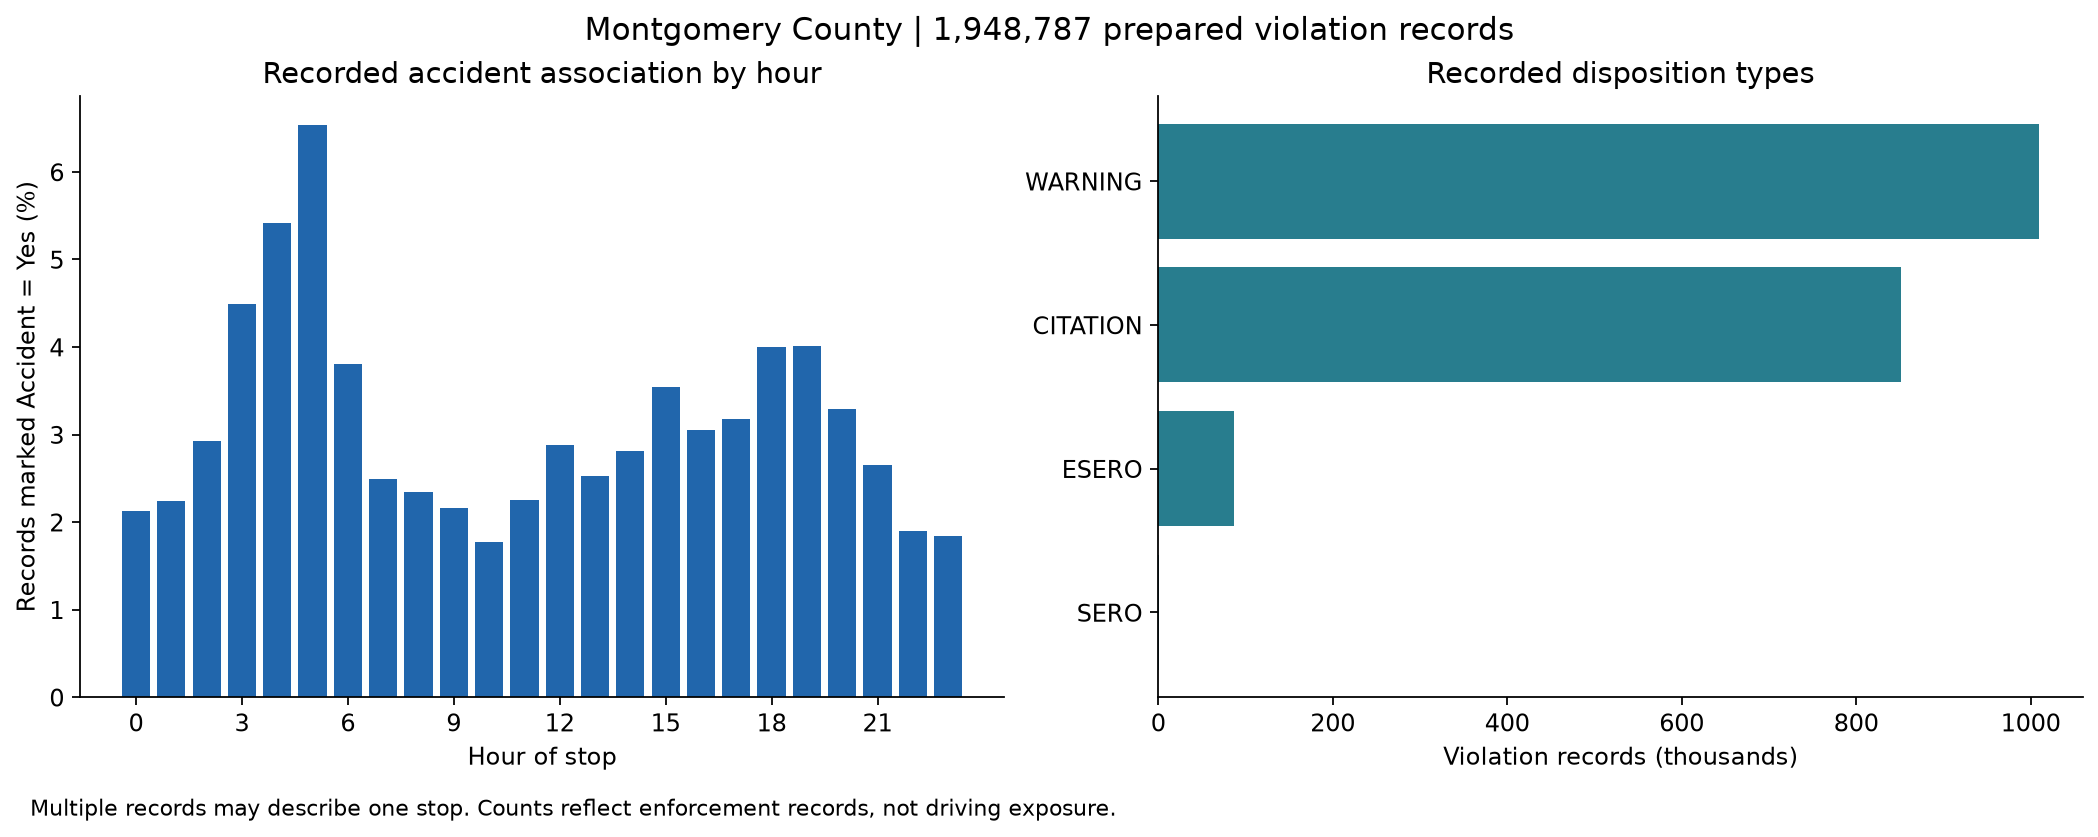

,hour,records,accident_records,accident_rate_pct
0,0,106135,2254,2.124
1,1,87793,1964,2.237
2,2,66232,1936,2.923
3,3,42799,1923,4.493
4,4,26253,1423,5.420
...,...,...,...,...
19,19,66935,2683,4.008
20,20,75360,2480,3.291
21,21,107827,2855,2.648
22,22,150483,2861,1.901


In [3]:
overview = plot_eda(data)
plt.close(overview)
from IPython.display import Image
display(Image(filename=str(ROOT / "assets/traffic-overview.png")))
hourly = group_summary(data.dropna(subset=["hour"]), "hour")
display(hourly.round(3))

In [4]:
dispositions = group_summary(data, "violation_type").sort_values("records", ascending=False)
display(dispositions.round(3))
by_year = data.assign(stop_year=data.stop_date.dt.year).groupby("stop_year").agg(
    records=("accident", "size"), accident_records=("accident", "sum"))
by_year["accident_rate_pct"] = 100 * by_year.accident_records / by_year.records
display(by_year.round(3))

,violation_type,records,accident_records,accident_rate_pct
3,WARNING,1009103,4022,0.399
0,CITATION,851523,49134,5.770
1,ESERO,87265,229,0.262
2,SERO,896,10,1.116


,records,accident_records,accident_rate_pct
stop_year,,,
2012,151153,3631,2.402
2013,190242,4616,2.426
2014,223497,4713,2.109
2015,235138,5008,2.130
2016,219494,5671,2.584
2017,198961,5762,2.896
2018,218029,5009,2.297
2019,188394,4858,2.579
2020,72229,3423,4.739


## Takeaways
Year-to-year differences can reflect changes in reporting, enforcement, and incomplete periods. The final observed year is partial. These data do not test whether speeding or DUI causes crashes: that question would require validated infraction definitions, driving exposure, and a different study design.